In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

np.random.seed(42)

n = 500

study_hours = np.random.uniform(1, 10, n).round(1)
attendance = np.random.randint(50, 101, n)
previous_marks = np.random.randint(30, 96, n)

noise = np.random.normal(0, 5, n)

final_marks = (
    3 * study_hours
    + 0.2 * attendance
    + 0.55 * previous_marks
    - 5
    + noise
)

final_marks = np.clip(final_marks, 0, 100).round(1)

df = pd.DataFrame({
    "Study_Hours": study_hours,
    "Attendance": attendance,
    "Previous_Marks": previous_marks,
    "Final_Marks": final_marks
})

df.to_csv("student_data.csv", index=False)

print("Dataset created successfully!")
print("Dataset Shape:", df.shape)
display(df.head())


Dataset created successfully!
Dataset Shape: (500, 4)


,Study_Hours,Attendance,Previous_Marks,Final_Marks
0,4.4,66,40,42.1
1,9.6,58,52,62.0
2,7.6,82,30,62.7
3,6.4,69,75,69.1
4,2.4,62,50,44.7


In [3]:

from google.colab import files

files.download("student_data.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:

print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Study_Hours     500 non-null    float64
 1   Attendance      500 non-null    int64  
 2   Previous_Marks  500 non-null    int64  
 3   Final_Marks     500 non-null    float64
dtypes: float64(2), int64(2)
memory usage: 15.8 KB

Missing Values:
Study_Hours       0
Attendance        0
Previous_Marks    0
Final_Marks       0
dtype: int64

Statistical Summary:


,Study_Hours,Attendance,Previous_Marks,Final_Marks
count,500.000000,500.000000,500.000000,500.000000
mean,5.488600,74.946000,62.690000,60.963200
std,2.690369,15.164796,19.015601,15.067364
min,1.000000,50.000000,30.000000,19.900000
25%,3.200000,61.000000,46.000000,49.925000
50%,5.600000,75.000000,62.000000,60.950000
75%,7.800000,87.250000,79.250000,71.750000
max,9.900000,100.000000,95.000000,98.100000


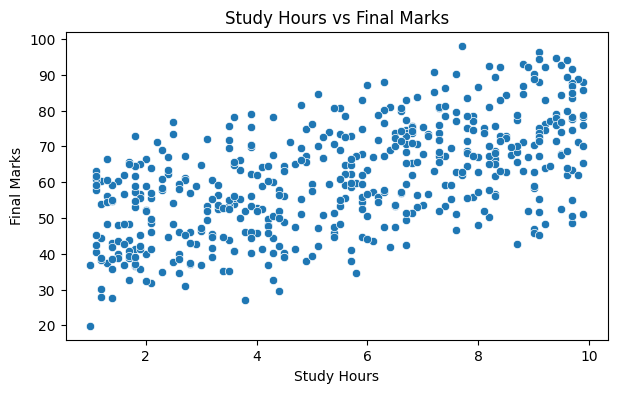

In [5]:

plt.figure(figsize=(7, 4))

sns.scatterplot(
    data=df,
    x="Study_Hours",
    y="Final_Marks"
)

plt.title("Study Hours vs Final Marks")
plt.xlabel("Study Hours")
plt.ylabel("Final Marks")
plt.show()


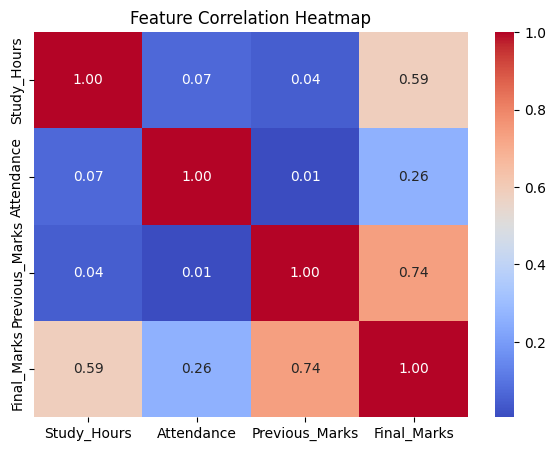

In [6]:

plt.figure(figsize=(7, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")
plt.show()


In [7]:

X = df[[
    "Study_Hours",
    "Attendance",
    "Previous_Marks"
]]

y = df["Final_Marks"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (400, 3)
Testing Data: (100, 3)


In [8]:

model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")


Model trained successfully!


In [9]:

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 3))


MAE: 3.65
RMSE: 4.91
R2 Score: 0.907


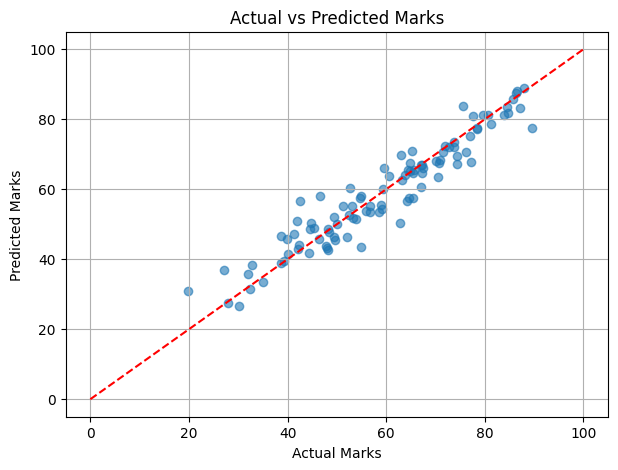

In [10]:

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot([0, 100], [0, 100], "r--")

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")
plt.grid(True)
plt.show()


In [11]:

student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [85],
    "Previous_Marks": [70]
})

prediction = model.predict(student)[0]
prediction = np.clip(prediction, 0, 100)

print(f"Predicted Final Marks: {prediction:.1f}/100")


Predicted Final Marks: 68.8/100


In [12]:

import joblib

joblib.dump(model, "model.pkl")

from google.colab import files
files.download("model.pkl")

print("Model saved successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model saved successfully!
